# 01 — Inventaire du corpus MaintiDoc

**Objectif :** comprendre la structure du manuel SAN avant de construire le RAG.

Ce notebook ne fait pas encore de recherche : il vérifie que le PDF est lisible,
compte les pages, les images et les tableaux, et sauvegarde un inventaire.

**Pourquoi commencer ici ?** Un pipeline RAG n'est jamais meilleur que son
extraction. Si le texte, les tableaux ou les figures sont mal extraits, les
embeddings et le modèle recevront des données dégradées.


## Étape 1 — Imports et chemins

On importe PyMuPDF, pandas et la configuration du projet. Le chemin du PDF est
déduit de `maintidoc.config`, donc il ne dépend pas du dossier courant du notebook.

La cellule vérifie aussi que le fichier existe et affiche la version de PyMuPDF.


In [1]:
from pathlib import Path

import pandas as pd
import pymupdf

from maintidoc.config import PDF_PATH

print("PDF :", PDF_PATH)
print("Existe :", PDF_PATH.exists())
print("PyMuPDF :", pymupdf.__version__)

PDF : D:\EMSI-RelatedGeneralFiles-S9\IA generative Visuelle + Textuelle\maintidoc\data\raw\Manuel_Maintenance_SAN_Projet_Integrateur.pdf
Existe : True
PyMuPDF : 2.1


### Lecture du résultat

On doit voir un chemin qui se termine par
`Manuel_Maintenance_SAN_Projet_Integrateur.pdf`, `Existe : True` et une version
de PyMuPDF récente (1.24 ou plus). Si `Existe : False`, le PDF n'est pas au bon
endroit : inutile de continuer.


## Étape 2 — Ouvrir le PDF et lire ses métadonnées

`pymupdf.open()` ouvre le document. On utilise un bloc `with` pour que le fichier
soit fermé automatiquement, même en cas d'erreur.

On affiche le nombre de pages, l'état de chiffrement, les métadonnées et le début
du texte de la page 1.


In [2]:
with pymupdf.open(PDF_PATH) as doc:
    print("Pages :", doc.page_count)
    print("Chiffré :", doc.needs_pass)
    print("Titre :", doc.metadata.get("title"))
    print("\nAperçu page 1 :\n")
    print(doc[0].get_text("text")[:500])

Pages : 9
Chiffré : 0
Titre : 

Aperçu page 1 :

MAINTiDOC  /  SAN-LAB 2000
MANUEL DE MAINTENANCE
D·UN SYSTEME SAN
PROJET INTEGRATEUR
Intelligence artificielle generative multimodale et agentique
Architecture SAN  |  Fibre Channel  |  Controleurs et disques
Alarmes  |  Diagnostic documentaire  |  Validation humaine
Document pedagogique fictif - SAN-LAB 2000
5 schemas integres, tableaux, procedures et cas d·interventions
Corpus de demonstration pour le Projet integrateur MaintiDoc
AVERTISSEMENT
Manuel fictif : ne remplace pas la notice officiel


### Lecture du résultat

Le document doit avoir **9 pages** et ne pas être chiffré. Le texte de la page 1
doit contenir « MAINTiDOC / SAN-LAB 2000 ». Si le texte est vide, le PDF n'a pas
de couche texte et il faudrait OCRiser.


## Étape 3 — Inventaire page par page

Pour chaque page, on collecte :

- le nombre de caractères ;
- le nombre d'images raster ;
- le nombre de tableaux détectés ;
- un aperçu du texte.

`page.find_tables()` peut échouer sur certaines pages : on l'entoure d'un
`try/except` pour ne pas interrompre l'inventaire.


In [3]:
rows = []

with pymupdf.open(PDF_PATH) as doc:
    for page in doc:
        texte = page.get_text("text")
        try:
            nb_tableaux = len(page.find_tables().tables)
        except Exception as exc:
            nb_tableaux = f"erreur:{type(exc).__name__}"

        rows.append({
            "page": page.number + 1,
            "caracteres": len(texte),
            "images": len(page.get_images(full=True)),
            "tableaux": nb_tableaux,
            "apercu": " ".join(texte.split())[:80],
        })

df_inventaire = pd.DataFrame(rows)
df_inventaire

,page,caracteres,images,tableaux,apercu
0,1,570,1,0,MAINTiDOC / SAN-LAB 2000 MANUEL DE MAINTENANCE...
1,2,1055,1,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
2,3,935,1,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
3,4,926,1,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
4,5,967,1,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
5,6,1253,1,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
6,7,1386,0,3,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
7,8,63,0,0,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...
8,9,1187,0,1,SAN-MAN-001 | MaintiDoc | Manuel pedagogique f...


### Lecture du résultat

On attend **9 lignes**. Les images apparaissent sur les pages 1 à 6 : la
couverture et les 5 schémas. Les pages 7 à 9 ne contiennent pas d'image.

La page 8 a très peu de caractères : c'est une page de séparation, pas une page
de contenu. On la garde dans l'inventaire mais elle ne produira pas de preuve.


## Étape 4 — Sauvegarder l'inventaire

On écrit `data/processed/inventory.csv`. Ce fichier est un artefact du projet :
il permet de vérifier plus tard que l'extraction n'a pas régressé.


In [4]:
from maintidoc.config import PROCESSED_DIR, ensure_dirs

ensure_dirs()
chemin = PROCESSED_DIR / "inventory.csv"
df_inventaire.to_csv(chemin, index=False, encoding="utf-8")

print("Fichier :", chemin)
print("Lignes :", len(df_inventaire))
print("Tableaux :", df_inventaire["tableaux"].sum())

Fichier : D:\EMSI-RelatedGeneralFiles-S9\IA generative Visuelle + Textuelle\maintidoc\data\processed\inventory.csv
Lignes : 9
Tableaux : 9


### Lecture du résultat

Le fichier contient 1 en-tête + 9 lignes de données. Le total des tableaux doit
valoir **9** : 1 sur les pages 2 à 6, 3 sur la page 7, 1 sur la page 9.


## Étape 5 — Les images

On extrait les images avec `doc.extract_image(xref)`. La couverture est marquée
`COVER`, les schémas `FIG-01` à `FIG-05`.

Pourquoi cette étape ? Les schémas contiennent des informations absentes du texte.
Ils seront indexés par CLIP et pourront être cités.


page 1 | image 1 | 2048×1072


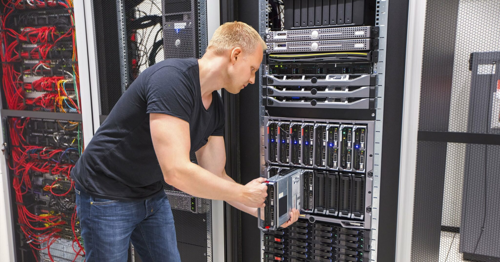

page 2 | image 1 | 1300×570


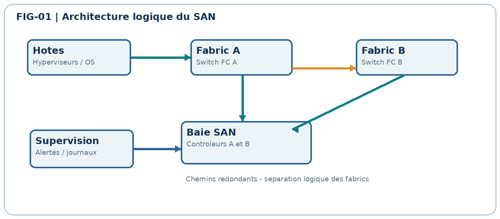

page 3 | image 1 | 1300×570


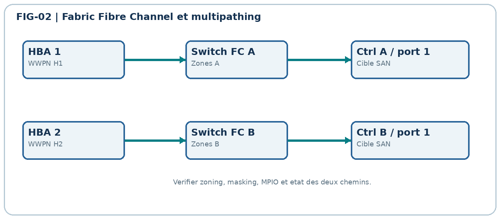

page 4 | image 1 | 1300×570


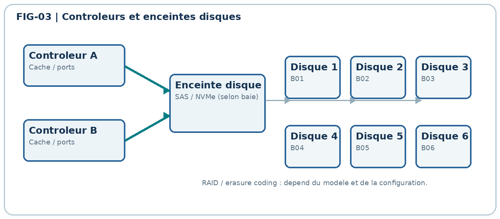

page 5 | image 1 | 1300×570


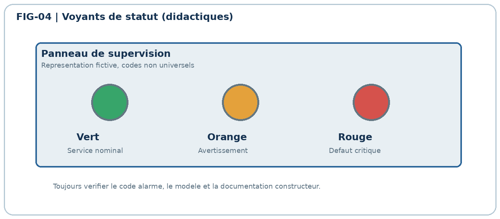

page 6 | image 1 | 1300×570


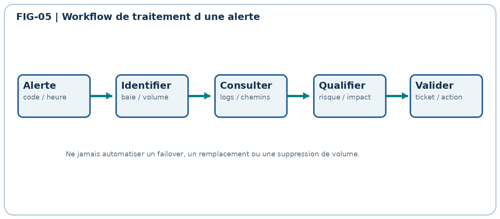

In [5]:
import io
from PIL import Image
from IPython.display import display

with pymupdf.open(PDF_PATH) as doc:
    for page in doc:
        for j, info in enumerate(page.get_images(full=True), 1):
            payload = doc.extract_image(info[0])
            with Image.open(io.BytesIO(payload["image"])) as im:
                print(f"page {page.number + 1} | image {j} | {im.width}×{im.height}")
                thumb = im.copy()
            thumb.thumbnail((500, 280))
            display(thumb)

### Lecture du résultat

On doit voir **6 images** : une couverture et 5 schémas. Les schémas sont larges
(1300×570) et lisibles. La couverture est exclue de l'index visuel : elle ne
répond pas à une question technique.


## Bilan

- 9 pages, 6 images, 9 tableaux.
- Page 8 = séparation, sans contenu.
- L'inventaire est sauvegardé.
- Les images sont identifiées.

**Étape suivante :** extraire les tableaux proprement et découper le texte en
passages indexables.
